<a href="https://colab.research.google.com/github/09StevenG/2022-ii-tutorial-git-repo-ejemplo/blob/main/CATIE_Extraer_DEM_30m_directo_de_Copernicus_para_zona_de_inter%C3%A9s_bbox.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import math
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

import rasterio
from rasterio.merge import merge

# Esta línea le dice a la librería que no ande listando carpetas remotas.
# Sin ella, leer desde la nube es varias veces más lento.
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"

print("rasterio", rasterio.__version__)

rasterio 1.5.2


In [ ]:
#funciones para extraer datos de COPERNICUS solo correrlo

def _url_tesela(lat, lon, glo=30):
    """Arma la dirección del archivo de una tesela de Copernicus."""
    res = "10" if glo == 30 else "30"          # resolución en segundos de arco
    ns = "N" if lat >= 0 else "S"
    ew = "E" if lon >= 0 else "W"
    nombre = (f"Copernicus_DSM_COG_{res}_"
              f"{ns}{abs(lat):02d}_00_{ew}{abs(lon):03d}_00_DEM")
    return f"https://copernicus-dem-{glo}m.s3.amazonaws.com/{nombre}/{nombre}.tif"


def obtener_dem(lat_min, lon_min, lat_max, lon_max):
    """Devuelve el DEM recortado al recuadro, como matriz y perfil."""
    teselas = [(la, lo)
               for la in range(math.floor(lat_min), math.floor(lat_max) + 1)
               for lo in range(math.floor(lon_min), math.floor(lon_max) + 1)]

    for glo in (30, 90):
        abiertas = []
        try:
            for la, lo in teselas:
                abiertas.append(rasterio.open(_url_tesela(la, lo, glo)))
        except Exception:
            for a in abiertas:
                a.close()
            print(f"GLO-{glo}: falta al menos una tesela de esta zona.")
            continue

        mosaico, transform = merge(
            abiertas, bounds=(lon_min, lat_min, lon_max, lat_max)
        )
        perfil = abiertas[0].profile
        for a in abiertas:
            a.close()

        perfil.update(driver="GTiff", count=1,
                      height=mosaico.shape[1], width=mosaico.shape[2],
                      transform=transform)

        print(f"Copernicus GLO-{glo} · {len(teselas)} tesela(s)")
        print(f"{mosaico.shape[2]} x {mosaico.shape[1]} celdas")
        return mosaico[0], perfil

    raise RuntimeError("Esa área no tiene cobertura en GLO-30 ni en GLO-90.")

In [ ]:
#area de interés
LAT_MIN, LAT_MAX = 15.00, 15.25      # sur, norte
LON_MIN, LON_MAX = -90.40, -90.10    # oeste, este

NOMBRE_AREA = "Baja Verapaz"         # para los títulos de los mapas

print(f"Área: {NOMBRE_AREA}")
print(f"  latitud  de {LAT_MIN} a {LAT_MAX}")
print(f"  longitud de {LON_MIN} a {LON_MAX}")

Área: Baja Verapaz
  latitud  de 15.0 a 15.25
  longitud de -90.4 a -90.1


In [ ]:
#acá se usan las funciones, queda la data del raster en z
z, perfil = obtener_dem(LAT_MIN, LON_MIN, LAT_MAX, LON_MAX)

Copernicus GLO-30 · 1 tesela(s)
1080 x 900 celdas


In [ ]:
#inspeccionar
print("Dimensiones :", z.shape, "(filas, columnas)")
print("CRS         :", perfil["crs"])
print("Valor nulo  :", perfil["nodata"])
print("Bandas      :", perfil["count"])
print("Tipo de dato:", perfil["dtype"])

Dimensiones : (900, 1080) (filas, columnas)
CRS         : EPSG:4326
Valor nulo  : None
Bandas      : 1
Tipo de dato: float32


In [ ]:
#verificar transform
t = perfil["transform"]

print(f"Tamaño de celda: {abs(t.a):.6f} x {abs(t.e):.6f} grados")
print(f"Es decir, unos {abs(t.a) * 111320:.0f} metros de lado")

Tamaño de celda: 0.000278 x 0.000278 grados
Es decir, unos 31 metros de lado


Archivo guardado como: Baja_Verapaz_DEM.tif


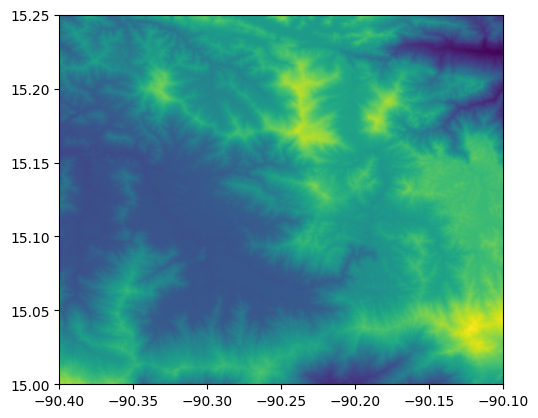

In [ ]:
from rasterio.plot import show #para verlo



# Definir el nombre del archivo de salida
nombre_archivo = f"{NOMBRE_AREA.replace(' ', '_')}_DEM.tif"

# 1. Guardar el raster a un archivo GeoTIFF local usando el perfil actualizado
with rasterio.open(nombre_archivo, 'w', **perfil) as dst:
    dst.write(z, 1)

print(f"Archivo guardado como: {nombre_archivo}")

# 2. Volver a abrir el raster y leerlo para verificar y mostrar el mapa
with rasterio.open(nombre_archivo) as src:
    data_leida = src.read(1)

    show(src)